# RQ4, part B: graph communities (Louvain) in sound space

**Scope: this notebook answers one half of research question 4, and only that half.** RQ4 asks whether our pseudo-genres are
real structure in the music or an artefact of k-means. It compares two methods:

| RQ4 | Method | Where |
|---|---|---|
| Method A | spherical k-means on the audio embeddings (pseudo-genres) | notebook 03 |
| **Method B** | **graph communities: Louvain on a kNN graph** | **this notebook** |
| Comparison | agreement of A and B, and whether the RQ1 genre results change with B's groups | separate step, not done here |

This notebook builds Method B and ends with the one number that links it to the other half (the ARI against the k-means
pseudo-genres). It does *not* draw the RQ4 conclusion.

**Deviation from the team briefing.** The briefing describes Method B on a *co-listening* graph. Here the graph is built from the
**audio embeddings** (an edge links tracks that sound alike). The Louvain code itself works unchanged on any weighted graph.

**Method in one line.** Embeddings → PCA (d dimensions) → unit length → k-nearest-neighbour graph (cosine) → our own Louvain with
resolution γ. Everything is implemented by hand with numpy only; networkx and scikit-learn appear only in the tests, as reference
implementations.

| § | Content |
|---|---|
| 1 | Implementation: preprocessing, PCA, kNN graph, modularity, Louvain (both phases), pipeline |
| 2 | Verification: tests against hand-made graphs and reference libraries |
| 3 | Data: the most played tracks |
| 4 | Choosing the PCA dimension d (not by modularity) |
| 5 | Sweep of k and γ: stability across seeds and neighbouring settings |
| 6 | Final run on 50,000 tracks, artist purity, hand-off number for the RQ4 comparison |

**Nodes.** The `N_SWEEP` (sweeps) and `N_FINAL` (final run) most played tracks of Yambda-50M that have an embedding. Brute-force kNN is
O(n²) and our Louvain is plain Python, so the full 848k tracks are out of reach; the most played tracks cover most of the listening.

*Prerequisite:* `python scripts/extract_embeddings_50m.py`. Tests run with `pytest` through `ipytest` if installed, otherwise directly.
Run time: about 30 minutes (mostly the sweep in §5). Memory: about 3 GB.

In [1]:
from pathlib import Path
from collections import deque
from dataclasses import dataclass
from itertools import combinations
import time
import numpy as np
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# ---------------- parameters (change here, then Run All) ----------------
N_SWEEP = 20_000                 # most played tracks used for choosing d, k and gamma
N_FINAL = 50_000                 # most played tracks in the final run
D_GRID = [10, 20, 30, 50, 100]   # PCA dimensions considered
K_GRID = [10, 15, 20, 30]        # neighbours per track
GAMMA_GRID = [0.5, 0.75, 1.0, 1.5, 2.0]   # Louvain resolution
SEEDS = [0, 1, 2, 3, 4]          # random node orders per setting
K_REF = 15                       # neighbourhood size for the neighbourhood-preservation check
N_SHUFFLES = 20                  # parallel analysis
KNN_CHUNK_MB = 256               # memory per block of the n x n similarity matrix
K_GENRE = 32                     # k-means pseudo-genres as in notebook 03 (for the hand-off ARI)
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {"louvain": "#264653", "kmeans": "#e9c46a", "shuffled": "#adb5bd"}

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA, PROC = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed"
print("project root:", ROOT)

project root: c:\Users\vikto\IdeaProjects\Computational-Tools-Project


## 1. Implementation

Rules for this section: no graph or community-detection library; numpy only for basic maths (matrix products, norms, SVD,
sorting). Readability before speed: plain Python loops where they make the algorithm easier to follow.

### 1a. Preprocessing and PCA
`preprocess` drops rows with NaN/inf or zero length and (with `l2=True`) scales every embedding to unit length, so only its
direction counts. PCA is fitted **once** at the largest d via the SVD of the centred data; the components are nested, so the
scores for a smaller d are just the first d columns. `parallel_analysis` suggests how many components carry more variance than
chance (columns shuffled independently).

In [2]:
def preprocess(X: np.ndarray, l2: bool = True) -> tuple[np.ndarray, np.ndarray]:
    """Validate raw embeddings and optionally scale every row to unit length.

    Rows with NaN/inf values or with zero length are dropped (they have no direction).
    Returns the cleaned matrix (float64) and a boolean mask of the rows that were kept.
    No centring here: PCA centres the data.
    """
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2:
        raise ValueError(f"expected a 2-d matrix, got shape {X.shape}")
    finite = np.isfinite(X).all(axis=1)
    norms = np.linalg.norm(np.where(finite[:, None], X, 0.0), axis=1)
    keep = finite & (norms > 0)
    if (~keep).any():
        print(f"preprocess: dropped {(~finite).sum():,} rows with NaN/inf and {(finite & (norms == 0)).sum():,} zero rows")
    X = X[keep]
    if l2:
        X = X / norms[keep][:, None]
    return X, keep


@dataclass
class PCAResult:
    scores: np.ndarray              # (n, d_max) coordinates on the first d_max components
    components: np.ndarray          # (d_max, D) principal directions (rows)
    mean: np.ndarray                # (D,) column means removed before the SVD
    explained_variance: np.ndarray  # (min(n, D),) variance along every component


def fit_pca(X: np.ndarray, d_max: int) -> PCAResult:
    """PCA via the SVD of the centred data, fitted once at the largest dimension.

    Components are nested, so the scores for any d <= d_max are scores[:, :d].
    Memory: the SVD of an n x D matrix needs about 3 copies of it (fine for n <= 50k, D = 128).
    For much larger n one would accumulate Xc.T @ Xc over row blocks and use np.linalg.eigh instead.
    """
    mean = X.mean(axis=0)
    Xc = X - mean
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    d_max = min(d_max, len(S))
    return PCAResult(scores=U[:, :d_max] * S[:d_max], components=Vt[:d_max], mean=mean,
                     explained_variance=S ** 2 / (len(X) - 1))


def parallel_analysis(X: np.ndarray, n_shuffles: int, seed: int, quantile: float = 0.95) -> tuple[np.ndarray, int]:
    """Horn's parallel analysis: which components carry more variance than chance?

    Every column is permuted independently (this keeps each column's distribution but destroys the
    correlations), the eigenvalues are recomputed, and a component counts as real if its eigenvalue is
    above the `quantile` of the shuffled eigenvalues at the same rank. Returns (thresholds, suggested d).
    """
    r = np.random.default_rng(seed)
    real = fit_pca(X, X.shape[1]).explained_variance
    shuffled = np.empty((n_shuffles, len(real)))
    for s in range(n_shuffles):
        Xs = np.empty_like(X)
        for col in range(X.shape[1]):
            Xs[:, col] = r.permutation(X[:, col])
        shuffled[s] = fit_pca(Xs, X.shape[1]).explained_variance
    thresholds = np.quantile(shuffled, quantile, axis=0)
    above = real > thresholds
    suggested = int(np.argmin(above)) if not above.all() else len(real)   # first rank that is not above chance
    return thresholds, suggested


def l2_normalize(Z: np.ndarray) -> np.ndarray:
    """Scale every row to unit length; rows of length 0 stay 0. Afterwards dot product = cosine similarity."""
    norms = np.linalg.norm(Z, axis=1, keepdims=True)
    return np.divide(Z, norms, out=np.zeros_like(Z, dtype=np.float64), where=norms > 0)

### 1b. Exact k nearest neighbours
After PCA the scores are scaled to unit length again (PCA re-centres and changes lengths), so a dot product is a cosine similarity.
The similarity matrix is n × n, so it is computed in blocks of rows (`KNN_CHUNK_MB` per block). Time is O(n² · d): seconds for
20,000 tracks, about six times more for 50,000.

In [3]:
def knn_cosine(Zn: np.ndarray, k: int, chunk_mb: int = 256) -> tuple[np.ndarray, np.ndarray]:
    """Exact k nearest neighbours by cosine similarity (rows of Zn must have unit length), self excluded.

    Brute force: all n x n similarities, O(n^2 * d) time. To bound memory, the similarity matrix is
    computed in blocks of rows, each block at most `chunk_mb` MB. Neighbours are sorted by decreasing
    similarity, ties broken by the smaller index, so the result is deterministic.
    Returns (idx, sims), both of shape (n, k).
    """
    n = len(Zn)
    if k >= n:
        print(f"knn_cosine: k = {k} >= n = {n}, using k = {n - 1}")
        k = n - 1
    rows_per_block = max(1, (chunk_mb * 2**20) // (n * 8))
    idx = np.empty((n, k), dtype=np.int64)
    sims = np.empty((n, k), dtype=np.float64)
    for start in range(0, n, rows_per_block):
        stop = min(start + rows_per_block, n)
        S = Zn[start:stop] @ Zn.T                                   # (block, n) cosine similarities
        S[np.arange(stop - start), np.arange(start, stop)] = -np.inf  # a track is not its own neighbour
        cand = np.argpartition(-S, k - 1, axis=1)[:, :k]            # the k largest, in arbitrary order
        cand_sims = np.take_along_axis(S, cand, axis=1)
        order = np.lexsort((cand, -cand_sims), axis=1)              # by -similarity, then by index
        idx[start:stop] = np.take_along_axis(cand, order, axis=1)
        sims[start:stop] = np.take_along_axis(cand_sims, order, axis=1)
    return idx, sims


def knn_jaccard(idx_a: np.ndarray, idx_b: np.ndarray) -> float:
    """Mean over nodes of the Jaccard overlap between two neighbour lists of the same nodes."""
    total = 0.0
    for a, b in zip(idx_a, idx_b):
        sa, sb = set(a.tolist()), set(b.tolist())
        total += len(sa & sb) / len(sa | sb)
    return total / len(idx_a)

### 1c. The graph
A graph is a **list of dicts**: `adj[i][j]` is the weight of edge i–j, stored in both directions. Iterating neighbours, looking up an
edge and adding weight during aggregation are each one obvious line, and memory stays small (about 25 entries per track).

The kNN graph links i and j if either is among the other's k nearest neighbours (**union**), with weight = cosine similarity clipped
at 0. Edges of weight 0 are not stored, and there are no self-loops in the input graph.

**Self-loop convention** (needed after aggregation): a self-loop is stored once as `adj[i][i]` and counts **twice** in the degree,
k_i = Σ_{j≠i} w_ij + 2·w_ii. Then m = Σ_i k_i / 2 counts every edge once.

In [4]:
@dataclass
class Graph:
    """Undirected weighted graph as a list of dicts: adj[i][j] = weight of edge i-j (stored in both dicts).

    A self-loop of node i is stored once, as adj[i][i]. It counts twice in the degree of i
    (k_i = sum_{j != i} w_ij + 2 w_ii), which is the convention that keeps modularity unchanged
    when communities are collapsed into single nodes (see `aggregate`).
    """
    adj: list[dict[int, float]]

    @property
    def n(self) -> int:
        return len(self.adj)


def graph_from_edges(n: int, edges: list[tuple[int, int, float]]) -> Graph:
    """Build a Graph from (i, j, w) triples; repeated edges add up, i == j makes a self-loop."""
    adj: list[dict[int, float]] = [dict() for _ in range(n)]
    for i, j, w in edges:
        adj[i][j] = adj[i].get(j, 0.0) + w
        if i != j:
            adj[j][i] = adj[j].get(i, 0.0) + w
    return Graph(adj)


def build_knn_graph(idx: np.ndarray, sims: np.ndarray) -> Graph:
    """Symmetric kNN graph: edge i-j if j is among i's neighbours OR i among j's (union).

    Weight = cosine similarity clipped at 0; edges of weight 0 are not stored; no self-loops.
    If both directions exist the larger weight is kept (for cosine they are equal anyway).
    """
    n = len(idx)
    adj: list[dict[int, float]] = [dict() for _ in range(n)]
    for i in range(n):
        for j, s in zip(idx[i].tolist(), sims[i].tolist()):
            w = max(s, 0.0)
            if w > 0.0 and j != i:
                w = max(w, adj[i].get(j, 0.0))
                adj[i][j] = w
                adj[j][i] = w
    return Graph(adj)


def degrees(g: Graph) -> np.ndarray:
    """Weighted degree k_i = sum of edge weights at i, a self-loop counted twice."""
    k = np.zeros(g.n)
    for i, nbrs in enumerate(g.adj):
        for j, w in nbrs.items():
            k[i] += 2 * w if j == i else w
    return k


def total_weight(g: Graph) -> float:
    """m = total edge weight, every edge (and self-loop) counted once = sum of degrees / 2."""
    return float(degrees(g).sum() / 2)


def connected_components(g: Graph) -> tuple[int, np.ndarray]:
    """Breadth-first search; returns (number of components, component id per node)."""
    comp = np.full(g.n, -1, dtype=np.int64)
    n_comp = 0
    for start in range(g.n):
        if comp[start] >= 0:
            continue
        comp[start] = n_comp
        queue = deque([start])
        while queue:
            i = queue.popleft()
            for j in g.adj[i]:
                if comp[j] < 0:
                    comp[j] = n_comp
                    queue.append(j)
        n_comp += 1
    return n_comp, comp

### 1d. Modularity (computed from scratch)

$$Q = \frac{1}{2m}\sum_{ij}\Big[A_{ij} - \gamma\frac{k_i k_j}{2m}\Big]\delta(c_i, c_j)
   \;=\; \sum_c \Big[\frac{L_c}{m} - \gamma\Big(\frac{\Sigma_{tot,c}}{2m}\Big)^2\Big]$$

L_c is the weight of the edges inside community c (each once, self-loops included), Σ_tot,c the summed degree of its nodes. The two
forms agree when A_ii = 2·w_ii, the convention above. γ > 1 favours smaller communities, γ < 1 larger ones. This function is
independent of the incremental bookkeeping in Louvain and is used for reporting and testing.

In [5]:
def modularity(g: Graph, labels: np.ndarray, resolution: float = 1.0) -> float:
    """Weighted modularity with resolution gamma, computed from scratch:

        Q = sum_c [ L_c / m  -  gamma * (Sigma_tot_c / 2m)^2 ]

    L_c = weight of the edges inside community c (each edge once, self-loops included),
    Sigma_tot_c = sum of the degrees of c's nodes. This equals
    (1/2m) sum_ij [A_ij - gamma k_i k_j / 2m] delta(c_i, c_j) with A_ii = 2 w_ii.
    A graph without edges has Q = 0 by definition.
    """
    m = total_weight(g)
    if m == 0:
        return 0.0
    k = degrees(g)
    inside: dict[int, float] = {}
    for i, nbrs in enumerate(g.adj):
        for j, w in nbrs.items():
            if j >= i and labels[i] == labels[j]:          # each edge once (j == i: self-loop)
                inside[labels[i]] = inside.get(labels[i], 0.0) + w
    sigma_tot: dict[int, float] = {}
    for i in range(g.n):
        sigma_tot[labels[i]] = sigma_tot.get(labels[i], 0.0) + k[i]
    return sum(inside.get(c, 0.0) / m - resolution * (s / (2 * m)) ** 2 for c, s in sigma_tot.items())

### 1e. Louvain phase 1: local moving

**Gain formula.** Take node i out of its community, so i is alone. Putting it into community C (Σ_tot(C) without i) adds the
edges from i into C, k_{i,C}, to the inside weight, and changes the degree term by
γ[(Σ_C + k_i)² − Σ_C² − k_i²]/(4m²) = γ Σ_C k_i/(2m²). So

$$\text{gain}(i \to C) = \frac{k_{i,C}}{m} - \gamma\,\frac{\Sigma_{tot}(C)\,k_i}{2m^2}$$

i's own self-loop is inside before and after, so it cancels. Moving i from D to C changes Q by gain(i→C) − gain(i→D∖i).

**Bookkeeping.** `sigma_tot[c]` is updated in place: subtract k_i when i leaves, add it when i joins. k_{i,C} is summed over i's
neighbours at every visit.

**Loop.** Nodes are visited in one seeded random order; full sweeps repeat until no node moves (or a sweep gains less than `tol`).
**Ties:** staying wins unless another community is better by more than 1e-12; between other communities the smallest id wins.

In [6]:
def insertion_gain(k_i_in: float, sigma_tot_c: float, k_i: float, m: float, resolution: float) -> float:
    """Modularity gain of putting an isolated node i into community C:

        gain = k_i,in / m  -  gamma * Sigma_tot(C) * k_i / (2 m^2)

    k_i,in = weight of the edges from i into C, Sigma_tot(C) = total degree of C without i.
    """
    return k_i_in / m - resolution * sigma_tot_c * k_i / (2 * m * m)


def local_moving(g: Graph, resolution: float, rng: np.random.Generator,
                 tol: float = 1e-10) -> tuple[np.ndarray, int, list[float]]:
    """Louvain phase 1: move single nodes to the neighbouring community with the largest gain.

    Starts from singletons. Nodes are visited in one seeded random order; full sweeps are repeated until
    no node moves or a sweep improves Q by less than `tol`. Returns (community per node, number of
    sweeps, Q after every sweep). Ties: staying is preferred, then the smallest community id.
    """
    n = g.n
    community = np.arange(n)
    m = total_weight(g)
    if m == 0:
        return community, 0, [0.0]
    k = degrees(g)
    sigma_tot = k.copy()                  # total degree per community (community ids = node ids)
    order = rng.permutation(n)
    q_trace = [modularity(g, community, resolution)]
    sweeps = 0
    while True:
        sweeps += 1
        moved, sweep_gain = 0, 0.0
        for i in order:
            own = community[i]
            # weight from i into each neighbouring community (the self-loop of i does not count)
            k_i_to: dict[int, float] = {}
            for j, w in g.adj[i].items():
                if j != i:
                    k_i_to[community[j]] = k_i_to.get(community[j], 0.0) + w
            sigma_tot[own] -= k[i]        # take i out of its community
            stay_gain = insertion_gain(k_i_to.get(own, 0.0), sigma_tot[own], k[i], m, resolution)
            best, best_gain = own, stay_gain
            for c in sorted(k_i_to):
                gain = insertion_gain(k_i_to[c], sigma_tot[c], k[i], m, resolution)
                if gain > best_gain + 1e-12:
                    best, best_gain = c, gain
            sigma_tot[best] += k[i]       # put i into the best community
            community[i] = best
            if best != own:
                moved += 1
                sweep_gain += best_gain - stay_gain
        q_trace.append(q_trace[-1] + sweep_gain)
        if moved == 0 or sweep_gain < tol:
            break
    return community, sweeps, q_trace

### 1f. Louvain phase 2: aggregation, and the full algorithm
Each community becomes one node. Edges between communities are summed; edges inside a community (and old self-loops) become the new
node's self-loop, stored once. With the degree convention of 1c every new degree is the sum of its members' degrees and m does not
change, so **modularity is preserved**: a partition of the old graph and the all-singletons partition of the new graph have the same
Q (tested in §2).

Louvain alternates phase 1 and phase 2 until a level changes nothing. The mapping is composed across levels so the final labels refer
to the original tracks, then relabelled to 0..C−1. At the end Q is recomputed from scratch and checked against the tracked value.

In [7]:
def relabel(labels: np.ndarray) -> np.ndarray:
    """Renumber labels to 0..C-1 in order of first appearance."""
    new_id: dict[int, int] = {}
    out = np.empty(len(labels), dtype=np.int64)
    for i, c in enumerate(labels.tolist()):
        if c not in new_id:
            new_id[c] = len(new_id)
        out[i] = new_id[c]
    return out


def aggregate(g: Graph, labels: np.ndarray) -> Graph:
    """Louvain phase 2: one node per community (labels must be 0..C-1).

    Edges between communities are summed. Edges inside a community, and old self-loops, become the
    self-loop of the new node, stored once. With the degree convention of `Graph` (self-loop counted
    twice) every new degree equals the sum of its members' degrees and m is unchanged, so modularity
    of a partition equals modularity of the singleton partition of the aggregated graph.
    """
    C = int(labels.max()) + 1 if g.n else 0
    adj: list[dict[int, float]] = [dict() for _ in range(C)]
    for i, nbrs in enumerate(g.adj):
        for j, w in nbrs.items():
            if j < i:
                continue                              # every undirected edge once
            a, b = int(labels[i]), int(labels[j])
            if a == b:
                adj[a][a] = adj[a].get(a, 0.0) + w
            else:
                adj[a][b] = adj[a].get(b, 0.0) + w
                adj[b][a] = adj[b].get(a, 0.0) + w
    return Graph(adj)


@dataclass
class LouvainResult:
    labels: np.ndarray            # community 0..C-1 of every original node
    modularity: float             # Q of the final partition on the original graph
    n_levels: int                 # number of aggregation levels that changed something
    sweeps_per_level: list[int]   # phase-1 sweeps at every level (including the last, unchanged one)
    q_trace: list[float]          # Q after every sweep, over all levels (never decreases)


def louvain(g: Graph, resolution: float = 1.0, seed: int = 0, tol: float = 1e-10) -> LouvainResult:
    """Louvain: alternate local moving (phase 1) and aggregation (phase 2) until a level changes nothing."""
    rng = np.random.default_rng(seed)
    labels = np.arange(g.n)               # community of every original node
    current = g
    sweeps_per_level: list[int] = []
    q_trace: list[float] = []
    while True:
        community, sweeps, trace = local_moving(current, resolution, rng, tol)
        sweeps_per_level.append(sweeps)
        q_trace.extend(trace if not q_trace else trace[1:])
        if len(np.unique(community)) == current.n:  # nobody moved: done
            break
        community = relabel(community)
        labels = community[labels]
        current = aggregate(current, community)
    labels = relabel(labels)
    q = modularity(g, labels, resolution)
    assert abs(q - q_trace[-1]) < 1e-8, f"bookkeeping error: tracked Q {q_trace[-1]} vs recomputed {q}"
    return LouvainResult(labels, q, len(sweeps_per_level) - 1, sweeps_per_level, q_trace)

### 1g. Pipeline and evaluation helpers
`cluster` = take d PCA columns → unit length → kNN graph → Louvain. Because the k nearest neighbours are nested in k, the sweep computes
the neighbour lists once per d at the largest k and slices them (`cluster_from_knn`). The adjusted Rand index (ARI) is written by hand
from the contingency table (1 = identical groupings, about 0 = chance agreement).

In [8]:
@dataclass
class ClusterResult:
    labels: np.ndarray
    n_clusters: int
    sizes: np.ndarray             # tracks per cluster, largest first
    modularity: float
    n_components: int             # connected components of the kNN graph
    n_levels: int
    sweeps_per_level: list[int]


def cluster_from_knn(idx: np.ndarray, sims: np.ndarray, k: int, resolution: float, seed: int) -> ClusterResult:
    """Graph + Louvain from precomputed neighbour lists (lists for a larger k can be sliced: they are nested)."""
    g = build_knn_graph(idx[:, :k], sims[:, :k])
    n_comp, _ = connected_components(g)
    res = louvain(g, resolution, seed)
    sizes = np.sort(np.bincount(res.labels))[::-1]
    return ClusterResult(res.labels, len(sizes), sizes, res.modularity, n_comp, res.n_levels, res.sweeps_per_level)


def cluster(Z_full: np.ndarray, d: int, k: int, resolution: float, seed: int) -> ClusterResult:
    """Steps 2-4: first d PCA columns -> unit length (dot = cosine) -> kNN graph -> Louvain."""
    Zn = l2_normalize(Z_full[:, :d])     # must happen after PCA: PCA re-centres and changes lengths
    idx, sims = knn_cosine(Zn, k, KNN_CHUNK_MB)
    return cluster_from_knn(idx, sims, k, resolution, seed)


def adjusted_rand_index(a: np.ndarray, b: np.ndarray) -> float:
    """Adjusted Rand index of two labelings (1 = identical, about 0 = chance), from the contingency table."""
    _, a = np.unique(a, return_inverse=True)
    _, b = np.unique(b, return_inverse=True)
    table = np.zeros((a.max() + 1, b.max() + 1))
    np.add.at(table, (a, b), 1)
    comb2 = lambda x: x * (x - 1) / 2
    sum_cells = comb2(table).sum()
    sum_a, sum_b = comb2(table.sum(axis=1)).sum(), comb2(table.sum(axis=0)).sum()
    expected = sum_a * sum_b / comb2(len(a))
    max_index = (sum_a + sum_b) / 2
    if max_index == expected:
        return 1.0
    return float((sum_cells - expected) / (max_index - expected))

## 2. Verification
Each test checks one property; reference libraries (networkx, scikit-learn) are imported **inside** the tests only.

| Test | Checks |
|---|---|
| `test_modularity_matches_networkx` | our Q = networkx Q (weights, self-loops, γ = 0.5/1/2) |
| `test_delta_q_matches_recomputation` | gain formula = Q_after − Q_before from scratch |
| `test_aggregation_preserves_modularity` | Q(partition) = Q(singletons of the aggregated graph); m and degrees preserved |
| `test_two_cliques_one_edge`, `test_ring_of_cliques` | the obvious communities are found exactly |
| `test_isolated_node`, `test_disconnected_graph`, `test_zero_weight_graph` | edge cases |
| `test_karate_club` | Q ≈ 0.42, same as networkx's Louvain |
| `test_q_monotone`, `test_same_seed_same_output`, `test_relabel_contiguous` | Q never decreases; determinism; labels 0..C−1 |
| `test_pca_matches_sklearn`, `test_knn_matches_exhaustive`, `test_knn_graph_properties`, `test_ari_matches_sklearn` | building blocks |
| `test_pipeline_blobs` | Gaussian blobs with known labels are recovered (ARI > 0.9), reproducibly |

In [9]:
# Test code only: networkx and scikit-learn are used here as reference implementations ("oracles").
# They are imported inside the test functions and never by the implementation above.

def random_graph(n: int, p: float, seed: int, self_loops: bool = True) -> Graph:
    """Random weighted graph (Erdos-Renyi with weights in (0, 1]), optionally with a few self-loops."""
    r = np.random.default_rng(seed)
    edges = [(i, j, float(r.uniform(0.1, 1.0))) for i in range(n) for j in range(i + 1, n) if r.random() < p]
    if self_loops:
        edges += [(i, i, float(r.uniform(0.1, 1.0))) for i in range(n) if r.random() < 0.2]
    return graph_from_edges(n, edges)


def to_networkx(g: Graph):
    import networkx as nx
    G = nx.Graph()
    G.add_nodes_from(range(g.n))
    for i, nbrs in enumerate(g.adj):
        for j, w in nbrs.items():
            if j >= i:
                G.add_edge(i, j, weight=w)
    return G


def as_communities(labels: np.ndarray) -> list[set[int]]:
    return [set(np.flatnonzero(labels == c).tolist()) for c in np.unique(labels)]


def cliques(sizes: list[int], ring: bool) -> tuple[Graph, np.ndarray]:
    """Cliques with unit weights, joined by one edge each in a chain (or a ring). Returns graph and true labels."""
    edges, truth, start, firsts = [], [], 0, []
    for c, s in enumerate(sizes):
        members = list(range(start, start + s))
        edges += [(a, b, 1.0) for x, a in enumerate(members) for b in members[x + 1:]]
        truth += [c] * s
        firsts.append(start)
        start += s
    for c in range(len(sizes) - 1 + int(ring)):
        a = firsts[c] + 1
        b = firsts[(c + 1) % len(sizes)]
        edges.append((a, b, 1.0))
    return graph_from_edges(start, edges), np.array(truth)

In [10]:
def test_modularity_matches_networkx():
    import networkx as nx
    for seed in range(10):
        g = random_graph(30, 0.15, seed)
        labels = np.random.default_rng(seed).integers(0, 4, g.n)
        for gamma in (0.5, 1.0, 2.0):
            ref = nx.community.modularity(to_networkx(g), as_communities(labels), weight="weight", resolution=gamma)
            assert abs(modularity(g, labels, gamma) - ref) < 1e-12


def test_delta_q_matches_recomputation():
    for seed in range(20):
        r = np.random.default_rng(seed)
        g = random_graph(20, 0.25, seed)
        m, k = total_weight(g), degrees(g)
        labels = r.integers(0, 5, g.n)
        gamma = float(r.choice([0.5, 1.0, 2.0]))
        for _ in range(20):
            i, target = int(r.integers(g.n)), int(r.integers(5))
            own = labels[i]
            # bookkeeping exactly as in local_moving
            k_i_to = {}
            for j, w in g.adj[i].items():
                if j != i:
                    k_i_to[labels[j]] = k_i_to.get(labels[j], 0.0) + w
            sigma = {c: k[labels == c].sum() for c in range(5)}
            sigma[own] -= k[i]
            predicted = (insertion_gain(k_i_to.get(target, 0.0), sigma[target], k[i], m, gamma)
                         - insertion_gain(k_i_to.get(own, 0.0), sigma[own], k[i], m, gamma))
            after = labels.copy(); after[i] = target
            assert abs(predicted - (modularity(g, after, gamma) - modularity(g, labels, gamma))) < 1e-12


def test_aggregation_preserves_modularity():
    for seed in range(10):
        g = random_graph(40, 0.1, seed)
        labels = relabel(np.random.default_rng(seed).integers(0, 6, g.n))
        agg = aggregate(g, labels)
        assert abs(total_weight(agg) - total_weight(g)) < 1e-12
        assert np.allclose(degrees(agg), [degrees(g)[labels == c].sum() for c in range(agg.n)])
        for gamma in (0.5, 1.0, 2.0):
            assert abs(modularity(g, labels, gamma) - modularity(agg, np.arange(agg.n), gamma)) < 1e-12

In [11]:
def test_two_cliques_one_edge():
    g, truth = cliques([6, 6], ring=False)
    res = louvain(g, 1.0, seed=0)
    assert res.labels.max() + 1 == 2
    assert adjusted_rand_index(res.labels, truth) == 1.0


def test_ring_of_cliques():
    g, truth = cliques([5] * 8, ring=True)
    res = louvain(g, 1.0, seed=0)
    assert res.labels.max() + 1 == 8
    assert adjusted_rand_index(res.labels, truth) == 1.0


def test_isolated_node():
    import networkx as nx
    g, _ = cliques([5, 5], ring=False)
    g = Graph(g.adj + [dict()])                      # node 10 has no edges
    res = louvain(g, 1.0, seed=0)
    assert np.sum(res.labels == res.labels[10]) == 1
    ref = nx.community.modularity(to_networkx(g), as_communities(res.labels), weight="weight")
    assert abs(res.modularity - ref) < 1e-12


def test_disconnected_graph():
    g1, _ = cliques([4, 4], ring=False)
    g2 = random_graph(15, 0.3, seed=3, self_loops=False)
    g = Graph(g1.adj + [{j + g1.n: w for j, w in nbrs.items()} for nbrs in g2.adj])
    _, comp = connected_components(g)
    res = louvain(g, 1.0, seed=0)
    for c in np.unique(res.labels):
        assert len(np.unique(comp[res.labels == c])) == 1


def test_zero_weight_graph():
    g = Graph([dict() for _ in range(5)])
    res = louvain(g, 1.0, seed=0)
    assert res.modularity == 0.0 and np.array_equal(res.labels, np.arange(5))


def test_karate_club():
    import networkx as nx
    G = nx.karate_club_graph()                       # unweighted here: networkx also ships edge weights
    g = graph_from_edges(G.number_of_nodes(), [(a, b, 1.0) for a, b in G.edges()])
    ours = max(louvain(g, 1.0, seed=s).modularity for s in range(5))
    ref = max(nx.community.modularity(G, nx.community.louvain_communities(G, weight=None, seed=s), weight=None)
              for s in range(5))
    print(f"karate club: our Q = {ours:.4f}, networkx Q = {ref:.4f}")
    assert ours >= 0.41 and abs(ours - ref) < 0.01


def test_q_monotone():
    for seed in range(10):
        res = louvain(random_graph(60, 0.08, seed), 1.0, seed=seed)
        assert all(b >= a - 1e-12 for a, b in zip(res.q_trace, res.q_trace[1:]))
        assert abs(res.q_trace[-1] - res.modularity) < 1e-10


def test_same_seed_same_output():
    g = random_graph(80, 0.06, seed=1)
    assert np.array_equal(louvain(g, 1.0, seed=7).labels, louvain(g, 1.0, seed=7).labels)


def test_relabel_contiguous():
    out = relabel(np.array([7, 7, 3, 9, 3]))
    assert out.tolist() == [0, 0, 1, 2, 1]

In [ ]:
def test_pca_matches_sklearn():
    from sklearn.decomposition import PCA
    X = np.random.default_rng(0).normal(size=(300, 12)) @ np.random.default_rng(1).normal(size=(12, 12))
    ours = fit_pca(X, 8)
    ref = PCA(n_components=8, svd_solver="full").fit_transform(X)
    assert np.allclose(np.abs(ours.scores), np.abs(ref), atol=1e-8)
    assert np.allclose(fit_pca(X, 5).scores, ours.scores[:, :5])          # nested


def test_knn_matches_exhaustive():
    from sklearn.neighbors import NearestNeighbors
    Zn = l2_normalize(np.random.default_rng(0).normal(size=(500, 10)))
    idx, sims = knn_cosine(Zn, 7, chunk_mb=1)                             # small chunks: several blocks
    S = Zn @ Zn.T; np.fill_diagonal(S, -np.inf)
    assert np.array_equal(idx, np.argsort(-S, axis=1, kind="stable")[:, :7])
    _, ref = NearestNeighbors(n_neighbors=8, metric="cosine").fit(Zn).kneighbors(Zn)
    assert all(set(a) == set(b[1:]) for a, b in zip(idx.tolist(), ref.tolist()))


def test_knn_graph_properties():
    Zn = l2_normalize(np.random.default_rng(2).normal(size=(300, 5)))
    idx, sims = knn_cosine(Zn, 10)
    g = build_knn_graph(idx, sims)
    for i, nbrs in enumerate(g.adj):
        assert i not in nbrs
        assert all(w > 0 and g.adj[j][i] == w for j, w in nbrs.items())
        assert len(nbrs) >= int((sims[i] > 0).sum())


def test_ari_matches_sklearn():
    from sklearn.metrics import adjusted_rand_score
    r = np.random.default_rng(0)
    for _ in range(20):
        a, b = r.integers(0, 5, 200), r.integers(0, 7, 200)
        b[:100] = a[:100]
        assert abs(adjusted_rand_index(a, b) - adjusted_rand_score(a, b)) < 1e-12


def test_pipeline_blobs():
    r = np.random.default_rng(0)
    centres = r.normal(size=(5, 20)) * 4
    truth = np.repeat(np.arange(5), 200)
    X = centres[truth] + r.normal(size=(1000, 20))
    Xp, _ = preprocess(X, l2=False)
    Z = fit_pca(Xp, 10).scores
    res = cluster(Z, d=10, k=15, resolution=1.0, seed=0)
    ari = adjusted_rand_index(res.labels, truth)
    print(f"blobs: {res.n_clusters} clusters, ARI = {ari:.3f}")
    assert ari > 0.9
    assert np.array_equal(res.labels, cluster(Z, 10, 15, 1.0, 0).labels)

: 

In [ ]:
# run all tests: with pytest (via ipytest) if installed, otherwise call them directly
test_functions = [f for name, f in list(globals().items()) if name.startswith("test_") and callable(f)]
try:
    import ipytest
    ipytest.autoconfig()
    exit_code = ipytest.run("-q", "-s")
    assert exit_code in (0, None), "some tests failed"
except ImportError:
    for f in test_functions:
        t0 = time.time(); f()
        print(f"passed {f.__name__}  ({time.time() - t0:.2f} s)")
print(f"{len(test_functions)} tests passed")

passed test_modularity_matches_networkx  (0.74 s)
passed test_delta_q_matches_recomputation  (0.11 s)
passed test_aggregation_preserves_modularity  (0.02 s)
passed test_two_cliques_one_edge  (0.00 s)
passed test_ring_of_cliques  (0.00 s)
passed test_isolated_node  (0.00 s)
passed test_disconnected_graph  (0.00 s)
passed test_zero_weight_graph  (0.00 s)
karate club: our Q = 0.4198, networkx Q = 0.4198
passed test_karate_club  (0.02 s)
passed test_q_monotone  (0.06 s)
passed test_same_seed_same_output  (0.02 s)
passed test_relabel_contiguous  (0.00 s)


## 3. Data: the most played tracks
Listens per track are counted over all listen events of Yambda-50M; tracks without an embedding are skipped. The sweep uses the
`N_SWEEP` most played tracks, the final run the `N_FINAL` most played (the sweep tracks are a subset). These are mostly mainstream
tracks, so the groups describe the heavily played part of the sound space.

In [ ]:
t0 = time.time()
ev = pq.read_table(DATA / "flat/50m/multi_event.parquet", columns=["item_id", "event_type"])
listen_items = ev.filter(pc.equal(ev["event_type"], "listen"))["item_id"].to_numpy()
del ev
emb_ids = np.load(PROC / "emb50m_item_ids.npy")
listens = np.bincount(listen_items, minlength=int(emb_ids.max()) + 1)[emb_ids]   # listens per embedded track
rank = np.argsort(-listens, kind="stable")[:N_FINAL]          # embedding rows, most played first
raw = np.load(PROC / "emb50m_embed.npy", mmap_mode="r")
X_all, keep = preprocess(np.asarray(raw[rank]), l2=True)
rank = rank[keep]
track_ids = emb_ids[rank]                                      # node i = track_ids[i]
for n in (N_SWEEP, N_FINAL):
    print(f"top {n:,} tracks: {listens[rank[:n]].sum() / len(listen_items):.1%} of all listens, "
          f"at least {listens[rank[n - 1]]:,} listens each")
print(f"embedding matrix {X_all.shape}  ({time.time() - t0:.0f} s)")

top 20,000 tracks: 63.5% of all listens, at least 416 listens each
top 50,000 tracks: 78.6% of all listens, at least 135 listens each
embedding matrix (50000, 128)  (2 s)


## 4. Choosing the PCA dimension d
**Not by modularity**: Q is not comparable across different graphs, and the graph changes with d. Two independent criteria instead:

* **parallel analysis**: components whose variance is above the 95th percentile of the same component in column-shuffled data;
* **neighbourhood preservation**: Jaccard overlap between each track's `K_REF` nearest neighbours at dimension d and at the full
  128 dimensions. Once it flattens, more dimensions change little about who is next to whom.

d is set to the grid value closest to the parallel-analysis suggestion; its two grid neighbours are kept for the sweep.

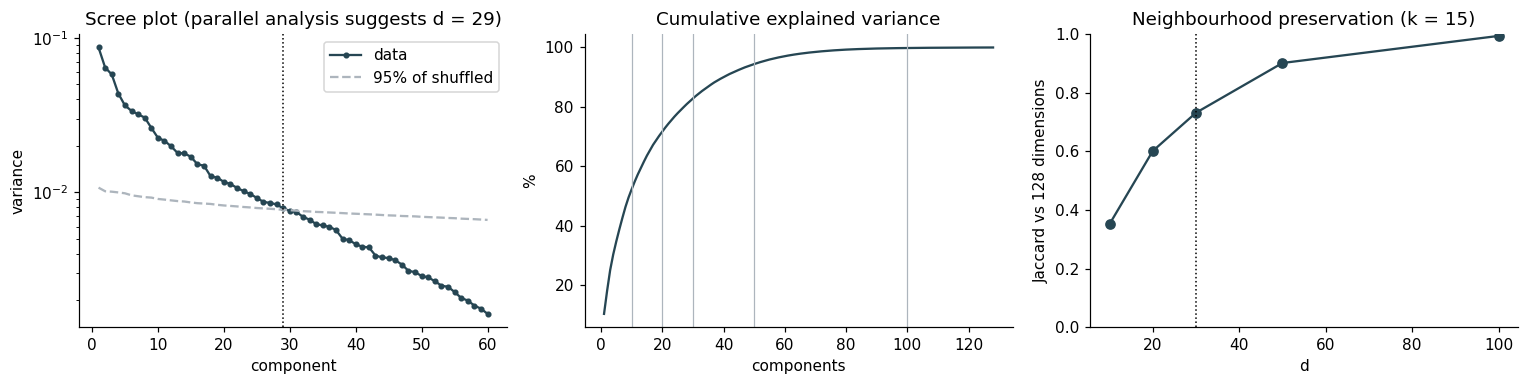

explained variance: {10: '52.3%', 20: '71.7%', 30: '82.8%', 50: '94.4%', 100: '99.8%'}
neighbourhood Jaccard: {10: 0.352, 20: 0.601, 30: 0.732, 50: 0.902, 100: 0.994}
chosen d = 30; sweep over d in [20, 30, 50]


In [ ]:
X_s = X_all[:N_SWEEP]
pca_s = fit_pca(X_s, max(D_GRID))
full = fit_pca(X_s, X_s.shape[1])
thresholds, d_pa = parallel_analysis(X_s, N_SHUFFLES, SEED)
ref_idx, _ = knn_cosine(l2_normalize(full.scores), K_REF, KNN_CHUNK_MB)
jac = {d: knn_jaccard(knn_cosine(l2_normalize(pca_s.scores[:, :d]), K_REF, KNN_CHUNK_MB)[0], ref_idx) for d in D_GRID}

ev_ = full.explained_variance
D_CHOSEN = min(D_GRID, key=lambda d: abs(d - d_pa))
pos = D_GRID.index(D_CHOSEN)
D_SWEEP = D_GRID[max(pos - 1, 0):pos + 2]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
r_ = np.arange(1, 61)
ax[0].plot(r_, ev_[:60], "o-", ms=3, color=COL["louvain"], label="data")
ax[0].plot(r_, thresholds[:60], "--", color=COL["shuffled"], label="95% of shuffled")
ax[0].axvline(d_pa, color="k", ls=":", lw=1)
ax[0].set(yscale="log", title=f"Scree plot (parallel analysis suggests d = {d_pa})", xlabel="component", ylabel="variance"); ax[0].legend()
ax[1].plot(np.arange(1, len(ev_) + 1), np.cumsum(ev_) / ev_.sum() * 100, color=COL["louvain"])
for d in D_GRID:
    ax[1].axvline(d, color=COL["shuffled"], lw=0.8)
ax[1].set(title="Cumulative explained variance", xlabel="components", ylabel="%")
ax[2].plot(D_GRID, [jac[d] for d in D_GRID], "o-", color=COL["louvain"])
ax[2].axvline(D_CHOSEN, color="k", ls=":", lw=1)
ax[2].set(title=f"Neighbourhood preservation (k = {K_REF})", xlabel="d", ylabel="Jaccard vs 128 dimensions", ylim=(0, 1))
plt.tight_layout(); plt.show()
print("explained variance:", {d: f"{ev_[:d].sum() / ev_.sum():.1%}" for d in D_GRID})
print("neighbourhood Jaccard:", {d: round(jac[d], 3) for d in D_GRID})
print(f"chosen d = {D_CHOSEN}; sweep over d in {D_SWEEP}")

## 5. Sweep of k and γ: which settings give stable groups?
For every d in `D_SWEEP`, k in `K_GRID`, γ in `GAMMA_GRID` and seed in `SEEDS` we run Louvain on the `N_SWEEP` tracks. Neighbour
lists are computed once per d at the largest k and sliced.

**Selection is by stability, never by modularity** (smaller k and different γ change Q for reasons unrelated to quality):
* **seed ARI**: mean ARI between the runs with different seeds (does the random node order matter?);
* **neighbour ARI**: mean ARI against the adjacent k, the adjacent γ and the adjacent d (same seed): are we on a plateau?

The chosen setting at `D_CHOSEN` has the highest mean of the two; Q and the number of clusters are reported for information only.

In [ ]:
labels_of, rows = {}, []
t_sweep = time.time()
for d in D_SWEEP:
    idx_d, sims_d = knn_cosine(l2_normalize(pca_s.scores[:, :d]), max(K_GRID), KNN_CHUNK_MB)
    for k in K_GRID:
        for gamma in GAMMA_GRID:
            for seed in SEEDS:
                t0 = time.time()
                res = cluster_from_knn(idx_d, sims_d, k, gamma, seed)
                labels_of[(d, k, gamma, seed)] = res.labels
                rows.append(dict(d=d, k=k, gamma=gamma, seed=seed, clusters=res.n_clusters, Q=res.modularity,
                                 components=res.n_components, levels=res.n_levels, seconds=time.time() - t0))
    print(f"d = {d} done ({time.time() - t_sweep:.0f} s)", flush=True)
runs = pd.DataFrame(rows)
print(f"{len(runs)} Louvain runs, median {runs['seconds'].median():.1f} s each; "
      f"kNN graphs connected in {(runs['components'] == 1).mean():.0%} of runs")

d = 20 done (355 s)


d = 30 done (709 s)


d = 50 done (1078 s)


300 Louvain runs, median 3.2 s each; kNN graphs connected in 75% of runs


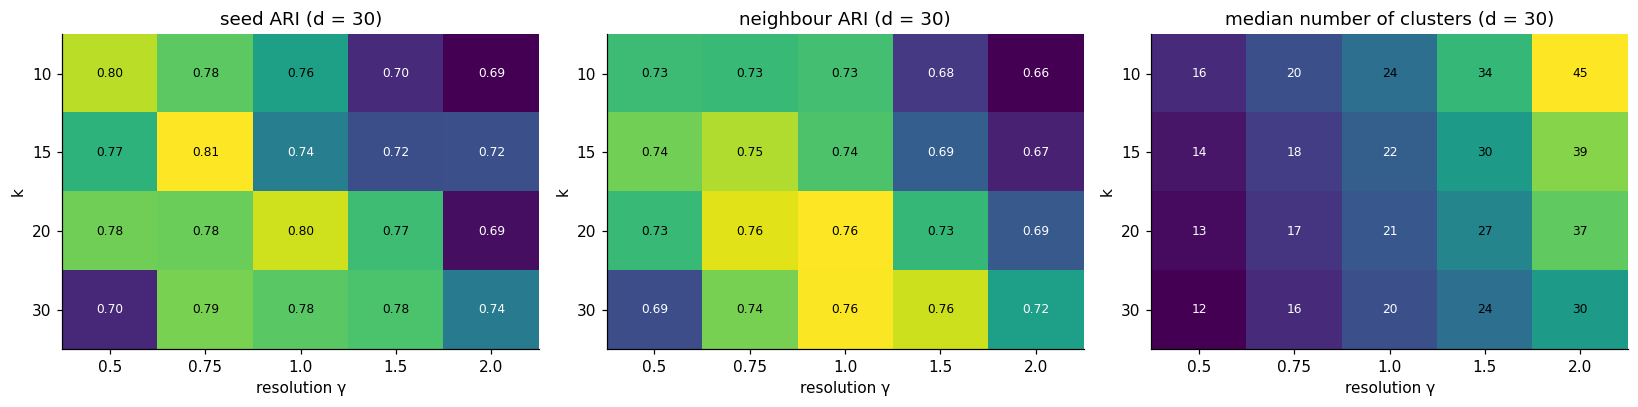

 d  k  gamma  clusters     Q  seed_ari  nbr_ari  stability
20 10  0.500    15.000 0.877     0.721    0.694      0.707
20 10  0.750    19.000 0.858     0.744    0.726      0.735
20 10  1.000    24.000 0.843     0.767    0.716      0.742
20 10  1.500    35.000 0.820     0.713    0.680      0.696
20 10  2.000    42.000 0.804     0.718    0.696      0.707
20 15  0.500    14.000 0.868     0.701    0.687      0.694
20 15  0.750    18.000 0.848     0.756    0.739      0.747
20 15  1.000    23.000 0.832     0.769    0.741      0.755
20 15  1.500    30.000 0.806     0.686    0.687      0.686
20 15  2.000    36.000 0.788     0.712    0.699      0.706
20 20  0.500    13.000 0.864     0.748    0.737      0.742
20 20  0.750    16.000 0.841     0.780    0.763      0.771
20 20  1.000    20.000 0.824     0.738    0.745      0.742
20 20  1.500    27.000 0.797     0.737    0.707      0.722
20 20  2.000    35.000 0.776     0.715    0.707      0.711
20 30  0.500    12.000 0.854     0.717    0.717      0.7

In [ ]:
def adjacent(grid, value):
    i = grid.index(value)
    return [grid[j] for j in (i - 1, i + 1) if 0 <= j < len(grid)]

rows = []
for d in D_SWEEP:
    for k in K_GRID:
        for gamma in GAMMA_GRID:
            seed_ari = np.mean([adjusted_rand_index(labels_of[(d, k, gamma, a)], labels_of[(d, k, gamma, b)])
                                for a, b in combinations(SEEDS, 2)])
            nbrs = ([(d, k2, gamma) for k2 in adjacent(K_GRID, k)] + [(d, k, g2) for g2 in adjacent(GAMMA_GRID, gamma)]
                    + [(d2, k, gamma) for d2 in adjacent(D_SWEEP, d)])
            nbr_ari = np.mean([adjusted_rand_index(labels_of[(d, k, gamma, s)], labels_of[(*nb, s)]) for nb in nbrs for s in SEEDS])
            sel = runs[(runs.d == d) & (runs.k == k) & (runs.gamma == gamma)]
            rows.append(dict(d=d, k=k, gamma=gamma, clusters=sel["clusters"].median(), Q=sel["Q"].median(),
                             seed_ari=seed_ari, nbr_ari=nbr_ari, stability=(seed_ari + nbr_ari) / 2))
stab = pd.DataFrame(rows)
best = stab[stab.d == D_CHOSEN].sort_values("stability", ascending=False).iloc[0]
K_CHOSEN, GAMMA_CHOSEN = int(best.k), float(best.gamma)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sub = stab[stab.d == D_CHOSEN]
for a, col, title, fmt in [(ax[0], "seed_ari", "seed ARI", "{:.2f}"), (ax[1], "nbr_ari", "neighbour ARI", "{:.2f}"),
                           (ax[2], "clusters", "median number of clusters", "{:.0f}")]:
    M = sub.pivot(index="k", columns="gamma", values=col).loc[K_GRID, GAMMA_GRID]
    im = a.imshow(M.to_numpy(), cmap="viridis", aspect="auto")
    for (i, j), v in np.ndenumerate(M.to_numpy()):
        a.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="w" if v < M.to_numpy().mean() else "k")
    a.set_xticks(range(len(GAMMA_GRID))); a.set_xticklabels(GAMMA_GRID); a.set_yticks(range(len(K_GRID))); a.set_yticklabels(K_GRID)
    a.set(title=f"{title} (d = {D_CHOSEN})", xlabel="resolution γ", ylabel="k")
plt.tight_layout(); plt.show()
print(stab.sort_values(["d", "k", "gamma"]).to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\nchosen: d = {D_CHOSEN}, k = {K_CHOSEN}, gamma = {GAMMA_CHOSEN} "
      f"(seed ARI {best.seed_ari:.3f}, neighbour ARI {best.nbr_ari:.3f}, about {best.clusters:.0f} clusters)")

## 6. Final run on the `N_FINAL` most played tracks
The chosen (d, k, γ) on the larger track set, with every seed. PCA is refitted on this set. We report the cluster sizes, the seed
stability, and **artist purity** as in notebook 03 (share of an artist's tracks in the artist's most common group, artists with at
least 5 tracks here), against shuffled labels as a baseline.

50,000 tracks, d = 30, k = 20, gamma = 1.0  (86 s)
clusters per seed: [28, 26, 26, 27, 26], Q per seed: [0.848, 0.849, 0.847, 0.848, 0.847], graph components: 1
mean ARI between seeds: 0.773


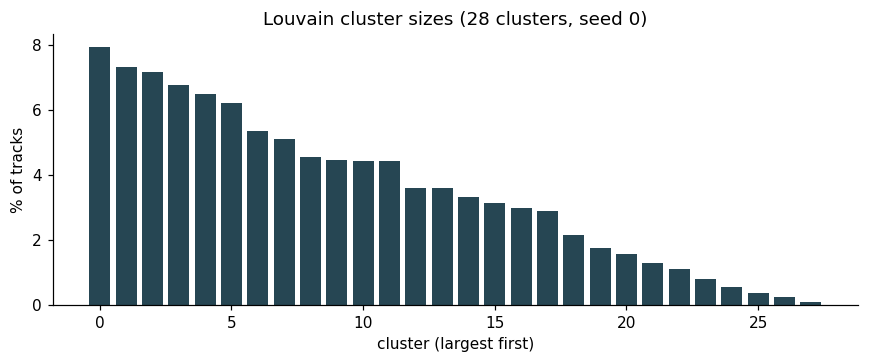

artist purity (2,550 artists with >= 5 tracks): Louvain 0.85  vs  shuffled labels 0.22


In [ ]:
t0 = time.time()
pca_f = fit_pca(X_all, D_CHOSEN)
idx_f, sims_f = knn_cosine(l2_normalize(pca_f.scores), K_CHOSEN, KNN_CHUNK_MB)
final = {s: cluster_from_knn(idx_f, sims_f, K_CHOSEN, GAMMA_CHOSEN, s) for s in SEEDS}
lab_L = final[SEEDS[0]].labels
seed_ari_f = np.mean([adjusted_rand_index(final[a].labels, final[b].labels) for a, b in combinations(SEEDS, 2)])
print(f"{len(X_all):,} tracks, d = {D_CHOSEN}, k = {K_CHOSEN}, gamma = {GAMMA_CHOSEN}  ({time.time() - t0:.0f} s)")
print(f"clusters per seed: {[final[s].n_clusters for s in SEEDS]}, Q per seed: {[round(float(final[s].modularity), 3) for s in SEEDS]}, "
      f"graph components: {final[SEEDS[0]].n_components}")
print(f"mean ARI between seeds: {seed_ari_f:.3f}")

# artist purity, first artist per track as in notebook 03
art = pd.read_parquet(DATA / "artist_item_mapping.parquet").drop_duplicates("item_id").set_index("item_id")["artist_id"]
artist = art.reindex(track_ids).fillna(-1).astype(np.int64).to_numpy()

def artist_purity(labels: np.ndarray, min_tracks: int = 5) -> tuple[float, int]:
    t = pd.DataFrame({"artist": artist, "group": labels})
    t = t[t["artist"] >= 0]
    size = t.groupby("artist").size(); t = t[t["artist"].isin(size[size >= min_tracks].index)]
    return float((t.groupby(["artist", "group"]).size().groupby("artist").max() / t.groupby("artist").size()).mean()), t["artist"].nunique()

pur_L, n_art = artist_purity(lab_L)
pur_shuf, _ = artist_purity(rng.permutation(lab_L))
sizes = final[SEEDS[0]].sizes
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(range(len(sizes)), sizes / sizes.sum() * 100, color=COL["louvain"])
ax.set(title=f"Louvain cluster sizes ({len(sizes)} clusters, seed {SEEDS[0]})", xlabel="cluster (largest first)", ylabel="% of tracks")
plt.tight_layout(); plt.show()
print(f"artist purity ({n_art:,} artists with >= 5 tracks): Louvain {pur_L:.2f}  vs  shuffled labels {pur_shuf:.2f}")

### Hand-off to the other half of RQ4: agreement with the k-means pseudo-genres
The pseudo-genres are recomputed with the procedure of notebook 03 (the same spherical k-means, k = `K_GENRE`, fitted on 150,000 random embedded
tracks, then every track assigned to its nearest centroid) and compared with the Louvain groups on the same tracks. This ARI is an
**input** to the RQ4 comparison, not its answer.

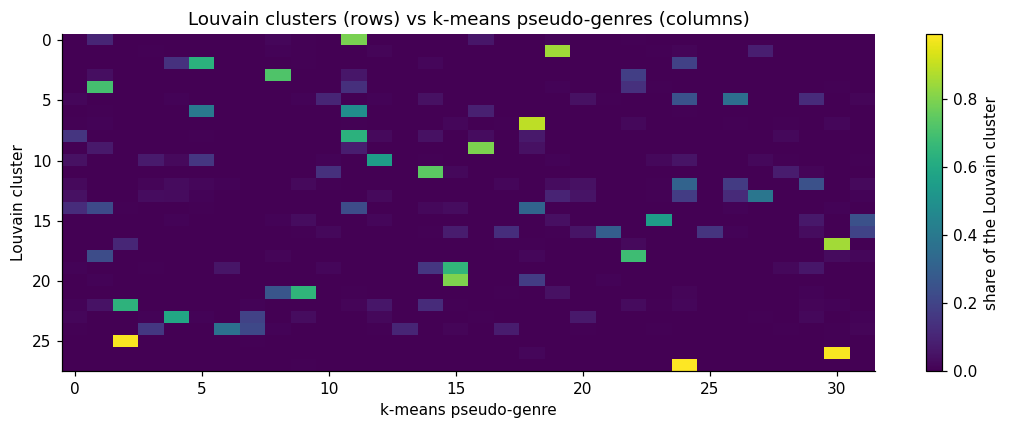

ARI Louvain vs k-means pseudo-genres: 0.428   (Louvain seeds among themselves: 0.773)
Louvain clusters whose largest k-means genre holds most of their tracks (> 50%): 75%
artist purity: Louvain 0.85 (28 groups), k-means 0.79 (32 groups), shuffled 0.22


In [ ]:
from scipy.sparse import csr_matrix   # used by the k-means of notebook 03 only, not by Louvain

def spherical_kmeans(X, k, seed, n_iter=60):
    """Copied unchanged from notebook 03 (Method A of RQ4)."""
    r = np.random.default_rng(seed); n = len(X)
    C = np.empty((k, X.shape[1]), dtype=np.float32); C[0] = X[r.integers(n)]
    dist = 1 - X @ C[0]
    for j in range(1, k):
        pr = np.maximum(dist, 0) ** 2; C[j] = X[r.choice(n, p=pr / pr.sum())]
        dist = np.minimum(dist, 1 - X @ C[j])
    labels = np.full(n, -1)
    for _ in range(n_iter):
        new = np.argmax(X @ C.T, axis=1)
        if (new == labels).mean() > 0.9995:
            labels = new; break
        labels = new
        sums = csr_matrix((np.ones(n, np.float32), (labels, np.arange(n))), shape=(k, n)) @ X
        nrm = np.linalg.norm(sums, axis=1, keepdims=True)
        empty = nrm[:, 0] == 0
        sums[empty] = X[r.integers(n, size=empty.sum())]; nrm[empty] = 1
        C = (sums / np.maximum(nrm, 1e-9)).astype(np.float32)
    return C, labels, float((X * C[labels]).sum(1).mean())

EN = np.load(PROC / "emb50m_norm.npy", mmap_mode="r")
fit_rows = np.sort(rng.choice(len(EN), 150_000, replace=False))
C_km, _, _ = spherical_kmeans(np.asarray(EN[fit_rows]), K_GENRE, SEED)
lab_K = np.argmax(np.asarray(EN[rank]) @ C_km.T, axis=1)
pur_K, _ = artist_purity(lab_K)
ari_LK = adjusted_rand_index(lab_L, lab_K)

# how do k-means genres spread over Louvain clusters?
table = pd.crosstab(lab_L, lab_K)
share_main = (table.max(axis=1) / table.sum(axis=1))
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow((table.T / table.sum(axis=1)).T.to_numpy(), aspect="auto", cmap="viridis")
plt.colorbar(im, ax=ax, label="share of the Louvain cluster")
ax.set(title="Louvain clusters (rows) vs k-means pseudo-genres (columns)", xlabel="k-means pseudo-genre", ylabel="Louvain cluster")
plt.tight_layout(); plt.show()
print(f"ARI Louvain vs k-means pseudo-genres: {ari_LK:.3f}   (Louvain seeds among themselves: {seed_ari_f:.3f})")
print(f"Louvain clusters whose largest k-means genre holds most of their tracks (> 50%): {(share_main > 0.5).mean():.0%}")
print(f"artist purity: Louvain {pur_L:.2f} ({len(sizes)} groups), k-means {pur_K:.2f} ({K_GENRE} groups), shuffled {pur_shuf:.2f}")

## Conclusion (N = 50,000 most played tracks; d = 30, k = 20, γ = 1.0)

**This notebook answers the Louvain half of RQ4 (Method B).** It shows that a hand-written Louvain on a kNN graph of the audio
embeddings finds stable, artist-coherent groups. Whether these groups confirm the k-means pseudo-genres is the RQ4 *comparison*, which
is not done here; this notebook only provides its inputs.

| Result | Value | Reading |
|---|---|---|
| Implementation checks | 17 of 17 tests pass; karate club Q = 0.420 (networkx 0.420); blobs recovered with ARI = 1.00 | the algorithm is correct |
| PCA dimension | parallel analysis suggests 29 → d = 30 (83 % of the variance; neighbourhood Jaccard 0.73 against all 128 dimensions) | the neighbourhood curve rises steadily, so d = 30 is a reasonable choice, not a sharp optimum |
| Stability over the sweep (20,000 tracks) | seed ARI 0.67-0.83; best and flattest region at γ = 0.75-1.0 for k = 15-30, at all three d | γ ≥ 1.5 (more, smaller groups) is clearly less stable |
| Final groups (50,000 tracks) | 26-28 clusters over 5 seeds, mean ARI between seeds 0.77, one connected graph | the coarse structure is reproducible; the borders between groups are partly arbitrary |
| Artist purity | 0.85 (k-means 0.79, shuffled 0.22) | tracks of one artist mostly land in one group, without the graph ever seeing artist IDs |
| **Hand-off: ARI Louvain vs k-means pseudo-genres** | **0.43**; in 75 % of the Louvain clusters most tracks come from one k-means genre | input for the RQ4 comparison, not interpreted here |

Modularity (about 0.85) is reported but was not used for any choice, because it is not comparable across graphs and resolutions.

**What the RQ4 comparison step still has to do.** (1) Judge the agreement of 0.43 against suitable baselines (e.g. k-means against itself
with other seeds, and Louvain seed stability of 0.77); (2) rerun the RQ1 genre metrics (distinct genres, entropy, novel-genre share)
with the Louvain groups, which needs a group for tracks outside the top 50,000 (e.g. the group of the nearest labelled track);
(3) optionally build Method B on a co-listening graph as described in the team briefing, using the same Louvain code.

**Limits.** Only the most played tracks (79 % of the listens), so the groups describe the mainstream part of the sound space. The graph
is built from sound, the same input as k-means, so some agreement is expected by construction. The k-means labels are refitted here with
the procedure of notebook 03 but a different random sample, so they are not identical to notebook 03's. 25 % of the sweep graphs had
more than one connected component (mainly small k); the final graph is connected.
